# H03. 밸브 상태에 따라 특정 구간의 압력이 다른가

| 항목 | 내용 |
|---|---|
| 질문 | 밸브가 나빠지면 60초 중 특정 순간의 압력이 달라질까? |
| 귀무가설 H0 | 밸브 상태 4개 그룹의 PS1 구간 평균(5초 × 12구간)은 모든 구간에서 같다 |
| 대립가설 H1 | 적어도 한 구간에서 그룹 간 분포가 다르다 |
| 검정 | 구간별 Kruskal-Wallis(12개 → Holm 보정) → 가장 큰 구간 Dunn, 효과 크기 ε², 60초 평균과 비교 |
| 출처 (EDA) | F13 원 파형, F14 상태별 평균 파형 |
| 데이터 | 원본 PS1.txt (100 Hz) → 5초 구간 평균 12개 |
| 왜 중요한가 | 60초 평균이 아니라 구간 특징(특징 v2)이 필요한지 판단 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

원본 PS1(100 Hz)을 1초 평균으로 줄여 밸브 상태별 평균 파형을 그립니다. 점선은 5초 구간 경계입니다.

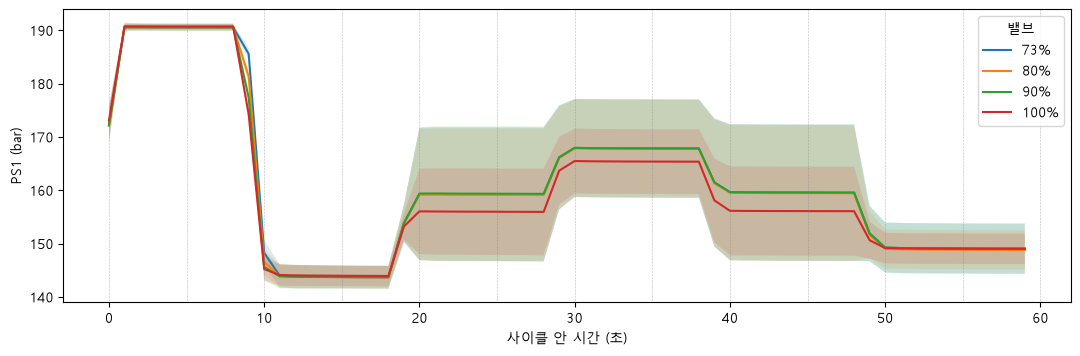

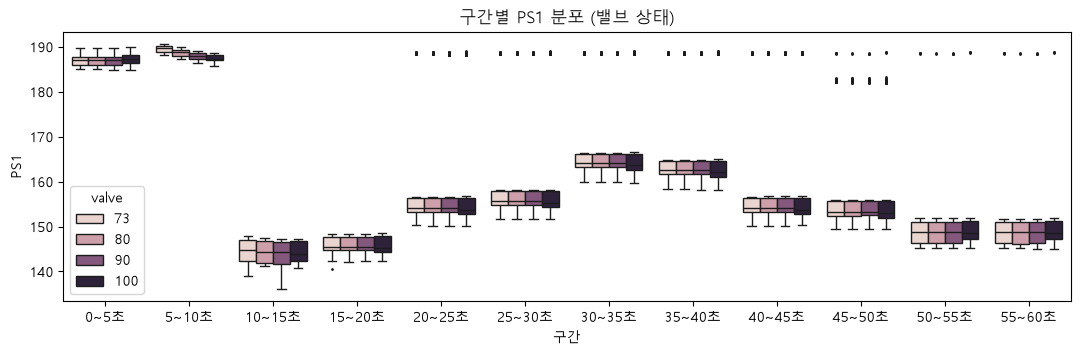

In [2]:
c = "valve_pct"
ps1 = raw("PS1")
p1 = ps1.reshape(len(ps1), 60, -1).mean(axis=2)          # 1초 평균 (2205 × 60)
seg = ps1.reshape(len(ps1), 12, -1).mean(axis=2)         # 5초 구간 평균 (2205 × 12)
SEG = [f"{k*5}~{k*5+5}초" for k in range(12)]
fig, ax = plt.subplots(figsize=(13, 3.8))
for v in sorted(cyc[c].unique()):
    m = (cyc[c] == v).values; mu, sd = p1[m].mean(0), p1[m].std(0)
    ax.plot(range(60), mu, label=f"{v}%"); ax.fill_between(range(60), mu - sd, mu + sd, alpha=0.15)
for s in range(0, 61, 5): ax.axvline(s, color="gray", lw=0.4, ls=":")
ax.set_xlabel("사이클 안 시간 (초)"); ax.set_ylabel("PS1 (bar)"); ax.legend(title="밸브"); plt.show()

fig, ax = plt.subplots(figsize=(13, 3.5))
d = pd.DataFrame(seg, columns=SEG).assign(valve=cyc[c].values).melt(id_vars="valve", var_name="구간", value_name="PS1")
sns.boxplot(data=d, x="구간", y="PS1", hue="valve", ax=ax, fliersize=1); ax.set_title("구간별 PS1 분포 (밸브 상태)"); plt.show()

**EDA로 본 것:** 상태별 곡선은 대부분 겹치고, **5~10초 부근에서만** 벌어집니다. 60초 전체 평균을 내면 이 차이가 묻힐 것으로 예상됩니다.

## 2. 기술통계 (구간별 평균)

In [3]:
display(pd.DataFrame(seg, columns=SEG).groupby(cyc[c].values).mean().round(1))

,0~5초,5~10초,10~15초,15~20초,20~25초,25~30초,30~35초,35~40초,40~45초,45~50초,50~55초,55~60초
73,186.9,189.5,144.7,145.7,159.3,160.6,167.9,166.5,159.6,158.0,149.1,149.1
80,186.9,188.7,144.3,145.7,159.1,160.5,167.8,166.5,159.5,157.9,148.9,148.8
90,186.9,187.9,144.1,145.7,159.4,160.7,167.9,166.5,159.6,158.0,149.1,149.0
100,187.2,187.4,144.3,145.8,156.0,157.5,165.4,163.9,156.1,155.0,149.1,149.0


## 5. 가설검정 (p-값) — 구간 12개

가정 확인과 정상성은 가장 차이가 큰 구간을 고른 뒤 그 구간으로 합니다(아래 3·4단계). 구간 12개를 검정하므로 Holm 보정을 합니다.

,구간,H,df,p,eps2,n,p_holm,효과
0,0~5초,41.7,3,4.76e-09,0.019,2205,4.76e-08,작음
1,5~10초,1150.3,3,4.44e-249,0.522,2205,5.32e-248,큼
2,10~15초,42.6,3,2.97e-09,0.019,2205,3.26e-08,작음
3,15~20초,0.1,3,9.94e-01,0.000,2205,9.94e-01,매우 작음
4,20~25초,10.3,3,1.62e-02,0.005,2205,8.12e-02,매우 작음
5,25~30초,9.2,3,2.73e-02,0.004,2205,1.09e-01,매우 작음
6,30~35초,12.1,3,7.11e-03,0.005,2205,4.27e-02,매우 작음
7,35~40초,16.2,3,1.03e-03,0.007,2205,9.29e-03,매우 작음
8,40~45초,13.7,3,3.38e-03,0.006,2205,2.36e-02,매우 작음
9,45~50초,14.9,3,1.86e-03,0.007,2205,1.49e-02,매우 작음


비교 — 60초 전체 평균(PS1_mean): H = 45.3, p = 7.84e-10, ε² = 0.021
가장 차이가 큰 구간: 5~10초


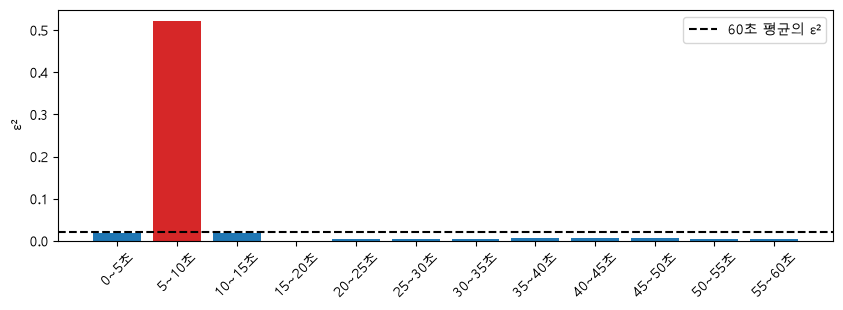

In [4]:
res = pd.DataFrame([dict(구간=SEG[k], **kruskal_test(seg[:, k], cyc[c])) for k in range(12)])
res["p_holm"] = holm(res["p"]); res["효과"] = res["eps2"].map(size_label)
overall = kruskal_test(cyc["PS1_mean"], cyc[c])
display(res.style.format({"H": "{:.1f}", "p": "{:.2e}", "p_holm": "{:.2e}", "eps2": "{:.3f}"}))
print(f"비교 — 60초 전체 평균(PS1_mean): H = {overall['H']:.1f}, p = {overall['p']:.2e}, ε² = {overall['eps2']:.3f}")
best = int(res["eps2"].idxmax()); print("가장 차이가 큰 구간:", SEG[best])
fig, ax = plt.subplots(figsize=(10, 3)); ax.bar(SEG, res["eps2"], color=["C3" if k == best else "C0" for k in range(12)])
ax.axhline(overall["eps2"], color="k", ls="--", label="60초 평균의 ε²"); ax.set_ylabel("ε²"); ax.legend(); plt.xticks(rotation=45); plt.show()

## 3. 가정 확인 (가장 큰 구간)

In [5]:
cyc["PS1_best_seg"] = seg[:, best]
tab, lev = assumption_table(cyc["PS1_best_seg"], cyc[c])
display(tab.style.format({"왜도": "{:.2f}", "K2": "{:.1f}", "정규성_p": "{:.2e}"}))
print(f"Levene W = {lev['W']:.2f}, p = {lev['p']:.2e} → 등분산: {lev['등분산']} → Kruskal-Wallis 사용")

,그룹,n,왜도,K2,정규성_p,정규분포
0,73,360,-0.23,511.0,1.11e-111,아니오
1,80,360,-0.28,286.4,6.40e-63,아니오
2,90,360,-0.34,211.2,1.41e-46,아니오
3,100,1125,-0.26,84.1,5.60e-19,아니오


Levene W = 13.08, p = 1.83e-08 → 등분산: 아니오 → Kruskal-Wallis 사용


## 4. 정상성 확인

사이클 순서대로 본 이 특징이 **정상(평균·분산이 시간에 따라 일정)**인지 확인합니다. ADF(H0: 비정상)와 KPSS(H0: 정상)는 질문이 반대라서 함께 봅니다.

- 비정상이거나 자기상관이 크면 "관측값이 서로 독립"이라는 검정의 가정이 약해집니다. 그래서 7단계에서 **50사이클 블록 평균으로 다시 검정**합니다.
- KPSS p가 0.01이나 0.10으로 나오면 경계값입니다. 각각 "0.01 이하", "0.10 이상"으로 읽습니다.


,특징,계열,ADF_p,KPSS_p,판정
0,PS1_best_seg,원값,0.0002,0.010,추세·구조변화(둘 다 기각)
1,PS1_best_seg,1차 차분,0.0000,0.100,정상
2,PS1_mean,원값,0.0002,0.100,정상
3,PS1_mean,1차 차분,0.0000,0.100,정상


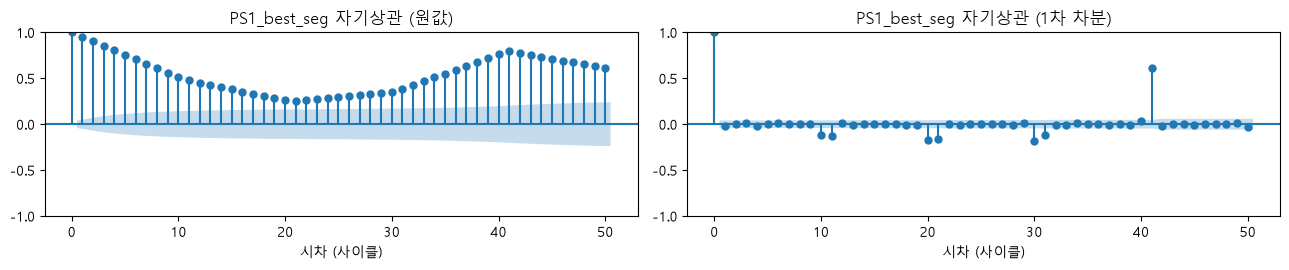

In [6]:
st = stationarity(cyc, ['PS1_best_seg', 'PS1_mean'])
display(st.style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
acf_plot(cyc['PS1_best_seg'], "PS1_best_seg 자기상관 (원값)", ax=axes[0])
acf_plot(cyc['PS1_best_seg'].diff(), "PS1_best_seg 자기상관 (1차 차분)", ax=axes[1])
plt.tight_layout(); plt.show()

## 6. 사후검정·효과 크기 (가장 큰 구간)

In [7]:
display(dunn_test(cyc["PS1_best_seg"], cyc[c]).style.format({"z": "{:.2f}", "p": "{:.2e}", "p_holm": "{:.2e}"}))
rbest = res.iloc[best]; print(f"{SEG[best]}: ε² = {rbest.eps2:.3f} ({size_label(rbest.eps2)}), 60초 평균의 {rbest.eps2 / overall['eps2']:.0f}배")

,쌍,z,p,p_holm,유의
0,73 vs 80,8.15,3.55e-16,3.55e-16,예
1,73 vs 90,18.07,5.26e-73,2.10e-72,예
2,73 vs 100,30.94,3.59e-210,2.15e-209,예
3,80 vs 90,9.92,3.42e-23,1.03e-22,예
4,80 vs 100,20.90,4.99e-97,2.49e-96,예
5,90 vs 100,8.69,3.52e-18,7.04e-18,예


5~10초: ε² = 0.522 (큼), 60초 평균의 25배


## 7. 블록 평균으로 재확인

In [8]:
b = block_means(cyc, "PS1_best_seg", c); rb = kruskal_test(b["PS1_best_seg"], b[c])
print(f"블록 {len(b)}개: H({rb['df']}) = {rb['H']:.1f}, p = {rb['p']:.3g}, ε² = {rb['eps2']:.3f}")

블록 143개: H(3) = 79.0, p = 5.12e-17, ε² = 0.556


## 8. 최종 판정

In [9]:
final = pd.DataFrame([dict(가설="H03", 구간=SEG[best], 통계량=f"H({int(rbest.df)}) = {rbest.H:.1f}", p_holm=rbest.p_holm,
    효과크기=f"ε² = {rbest.eps2:.3f} ({size_label(rbest.eps2)})", 평균의_효과=f"ε² = {overall['eps2']:.3f}",
    블록평균_p=rb["p"], 판정="H0 기각" if (rbest.p_holm < ALPHA and rb["p"] < ALPHA) else "H0 유지")])
display(final)
save_result("H03", title="밸브 상태 → 압력 구간", test="Kruskal-Wallis (12구간, Holm)", stat=final.통계량[0], p=rbest.p_holm,
            effect=f"{SEG[best]} ε² = {rbest.eps2:.2f} (평균 {overall['eps2']:.2f})", verdict=final.판정[0])

,가설,구간,통계량,p_holm,효과크기,평균의_효과,블록평균_p,판정
0,H03,5~10초,H(3) = 1150.3,5.322132e-248,ε² = 0.522 (큼),ε² = 0.021,5.119588e-17,H0 기각


저장: results/H03.json


## 9. 해석과 결정

- 밸브 차이는 **5~10초 구간에 몰려** 있습니다. 이 구간의 ε²는 약 0.52(큼)인데, 60초 전체 평균은 약 0.02(작음)입니다.
- 15초 이후 구간은 대부분 차이가 없거나 매우 작습니다.
- **결정:** 밸브 진단에는 **구간 특징(특징 v2)이 필수**입니다. 특징 v2를 채택한 가장 강한 통계적 근거입니다.